# TCR vs Bias vs Temperature

Expected folder layout (either level can be switched off with `USE_TEMP` / `USE_BIAS`):

```
Parent Folder/{Temp}K/{Bias}V/*.csv     USE_TEMP = True,  USE_BIAS = True
Parent Folder/{Bias}V/*.csv             USE_TEMP = False, USE_BIAS = True
Parent Folder/{Temp}K/*.csv             USE_TEMP = True,  USE_BIAS = False
```

### Configuration

In [ ]:
from pathlib import Path

DATA_ROOT = Path("~/Desktop/UCSDPDCv2/data").expanduser()
PARENT_GLOB = "TCR_Temp_Bias*"        # must match exactly one folder inside DATA_ROOT
FILE_GLOB = "*.csv"
DELIMITER = ";"

USE_TEMP = True                      # Parent/{Temp}K/...
USE_BIAS = True                     # .../{Bias}V/...

ESTIMATOR = "cluster"                # "cluster" | "mode" | "median"
MAIN_CLUSTER = "low"                 # cluster estimator: "majority" | "low" | "high"
MIN_SEPARATION = 0.3                 # decades between cluster medians to call data bimodal
MIN_D = 4.0                          # Ashman's D needed to call data bimodal

SHOW_MINORITY = True                 # hollow markers: median of the other cluster
SHOW_SPREAD = True                   # error bars: 16-84 percentile of the main cluster
LOG_Y = True
FIG_SCALE = 3

SAVE_PLOTS = True                    # save the main-cluster counts and off-pixel plots
SAVE_DIR = None                      # None: save inside the PARENT_GLOB folder, or set a Path

In [88]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Plot Styling

In [89]:
# Shared plot style: this cell is identical in the DSUM and TCR notebooks.
import math
from matplotlib import cm, colors

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "lines.linewidth": 1.2,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.titlesize": 10,
    "axes.formatter.limits": (-3, 4),       # scientific notation outside 1e-3 ... 1e4
    "axes.formatter.use_mathtext": True,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# Colour language: blue = bias, warm (yellow -> red) = temperature; darker = higher.
BIAS_CMAP = colors.LinearSegmentedColormap.from_list(
    "bias_blue", ["#9ecae1", "#6baed6", "#2f7fc1", "#0f4c9c", "#0a2f6e", "#05163f"])
TEMP_CMAP = colors.LinearSegmentedColormap.from_list(
    "temp_ylorrd", plt.get_cmap("YlOrRd")(np.linspace(0.30, 1.0, 256)))
HUES = {"bias": (BIAS_CMAP, "Bias (V)"), "temp": (TEMP_CMAP, "Temperature (K)")}


def hue_norm(values):
    lo, hi = float(min(values)), float(max(values))
    return colors.Normalize(lo, hi) if hi > lo else colors.Normalize(lo - 1, hi)   # a single value gets the darkest colour


def hue_color(kind, value, values):
    """Colour of `value` for kind 'bias' or 'temp'; `values` is every value in the figure."""
    return HUES[kind][0](hue_norm(values)(value))


def add_hue_colorbar(fig, axes, kind, values):
    cmap, label = HUES[kind]
    cb = fig.colorbar(cm.ScalarMappable(hue_norm(values), cmap), ax=axes, pad=0.02)
    cb.set_label(label)
    ticks = sorted(set(values))
    if len(ticks) <= 12:
        cb.set_ticks(ticks)
        cb.ax.set_yticklabels([f"{t:g}" for t in ticks])
    cb.ax.tick_params(length=2)


def pdc_grid(n, scale=3.0, sharey=True):
    """Axes for n PDCs: two columns, filled top-left, top-right, bottom-left, bottom-right (one column if n = 1)."""
    ncols = 1 if n == 1 else 2
    nrows = math.ceil(n / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(1.25 * scale * ncols, scale * nrows), squeeze=False,
                            sharex=True, sharey=sharey, layout="constrained")
    flat = list(axs.ravel())
    for ax in flat[n:]:
        ax.set_visible(False)
    flat = flat[:n]
    for i, ax in enumerate(flat):
        if i + ncols >= n:                  # nothing below this panel: keep its x tick labels
            ax.tick_params(labelbottom=True)
    return fig, flat


def label_grid(axs, pdcs, xlabel, ylabel, sharey=True):
    """PDC titles, x label under each column, y label on the left column (every panel if y is not shared)."""
    n = len(axs)
    ncols = 1 if n == 1 else 2
    for i, (ax, pdc) in enumerate(zip(axs, pdcs)):
        ax.set_title(f"PDC {pdc}")
        if i + ncols >= n:
            ax.set_xlabel(xlabel)
        if i % ncols == 0 or not sharey:
            ax.set_ylabel(ylabel)

### Find the files

In [90]:
FOLDER_RE = {
    "temp": re.compile(r"^([-+]?\d+(?:\.\d+)?)\s*K$", re.I),
    "bias": re.compile(r"^([-+]?\d+(?:\.\d+)?)\s*V$", re.I),
}


def find_parent(data_root, pattern):
    matches = sorted(p for p in data_root.glob(pattern) if p.is_dir())
    if len(matches) != 1:
        raise ValueError(f"'{pattern}' matched {len(matches)} folders in {data_root}: {[m.name for m in matches]}")
    return matches[0]


def discover(parent, levels, file_glob):
    """Walk parent/{level1}/{level2}/... and return a DataFrame with one row per file."""
    rows, skipped = [], []

    def walk(path, remaining, meta):
        if not remaining:
            rows.extend({**meta, "file": f} for f in sorted(path.glob(file_glob)))
            return
        name, pattern = remaining[0]
        for d in sorted(p for p in path.iterdir() if p.is_dir()):
            m = pattern.match(d.name)
            if m:
                walk(d, remaining[1:], {**meta, name: float(m.group(1))})
            else:
                skipped.append(d)

    walk(parent, levels, {})
    if skipped:
        print(f"Skipped {len(skipped)} folders that do not match the expected names, e.g. {skipped[0].name}")
    return pd.DataFrame(rows)


levels = [(k, FOLDER_RE[k]) for k, on in (("temp", USE_TEMP), ("bias", USE_BIAS)) if on]
if not levels:
    raise ValueError("Enable at least one of USE_TEMP / USE_BIAS")

parent = find_parent(DATA_ROOT, PARENT_GLOB)
files = discover(parent, levels, FILE_GLOB)
if files.empty:
    raise ValueError("No files found; check PARENT_GLOB, FILE_GLOB and the USE_TEMP / USE_BIAS settings")
axes_present = [k for k, _ in levels]
print(f"Running {len(files)} files from {parent.name} ({' x '.join(axes_present)})")
if files.duplicated(axes_present, keep=False).any():
    print(f"Warning: some {' / '.join(axes_present)} conditions appear in more than one file; they are plotted as separate points")

Running 23 files from TCR_Temp_Bias (temp x bias)


### Per-file summary (robust to a second pixel population)

In [91]:
def otsu_split(y):
    """Best 2-cluster split of 1D values (minimum within-class variance); returns mask of the upper cluster."""
    order = np.argsort(y)
    s = y[order]
    n = len(s)
    c1, c2 = np.cumsum(s), np.cumsum(s ** 2)
    k = np.arange(1, n)
    m_lo = c1[:-1] / k
    m_hi = (c1[-1] - c1[:-1]) / (n - k)
    cost = (c2[:-1] - k * m_lo ** 2) + ((c2[-1] - c2[:-1]) - (n - k) * m_hi ** 2)
    upper = np.zeros(n, bool)
    upper[order[k[np.argmin(cost)]:]] = True
    out = np.zeros(n, bool)
    out[order] = upper
    return out


def log_mode(y):
    """Peak of a Gaussian KDE of log10 values."""
    if y.size < 2 or np.ptp(y) == 0:
        return y.mean()
    bw = np.clip(0.9 * min(y.std(), np.subtract(*np.percentile(y, [75, 25])) / 1.34 or y.std()) * y.size ** -0.2, 0.03, 0.15)
    grid = np.linspace(y.min() - 3 * bw, y.max() + 3 * bw, 512)
    dens = np.exp(-0.5 * ((grid[:, None] - y) / bw) ** 2).sum(axis=1)
    return grid[np.argmax(dens)]


def summarize(tcr, estimator="cluster", main_cluster="majority", min_sep=0.3, min_d=4.0):
    """Collapse one pixel-TCR array to a single value plus bimodality diagnostics."""
    tcr = np.asarray(tcr, float)
    tcr = tcr[np.isfinite(tcr)]
    live = tcr[tcr > 0]
    out = dict(
        n=tcr.size,
        n_off=tcr.size - live.size,
        median=np.median(tcr) if tcr.size else np.nan,
        value=np.nan,
        p16=np.nan,
        p84=np.nan,
        bimodal=False,
        minor=np.nan,
        minor_frac=0.0,
    )
    if live.size == 0:
        return out

    y = np.log10(live)
    groups = [live]
    if live.size >= 4:
        up = otsu_split(y)
        a, b = y[~up], y[up]
        sep = np.median(b) - np.median(a)
        d = np.sqrt(2) * (b.mean() - a.mean()) / np.sqrt(a.var() + b.var() + 1e-12)
        if sep >= min_sep and d >= min_d:
            groups = [live[~up], live[up]]
            out["bimodal"] = True

    if estimator == "cluster":
        pick = {"majority": max(groups, key=len), "low": groups[0], "high": groups[-1]}[main_cluster]
        out["value"] = np.median(pick)
    elif estimator == "mode":
        out["value"] = 10 ** log_mode(y)
    elif estimator == "median":
        out["value"] = out["median"]
    else:
        raise ValueError(f"Unknown estimator '{estimator}'")

    log_value = np.log10(max(out["value"], 1e-9))
    main = min(groups, key=lambda g: abs(np.log10(np.median(g)) - log_value))
    out["p16"], out["p84"] = np.percentile(main, [16, 84])
    if out["bimodal"]:
        other = next(g for g in groups if g is not main)
        out["minor"] = np.median(other)
        out["minor_frac"] = other.size / live.size
    return out


def build_results(files):
    rows = []
    for _, r in files.iterrows():
        data = pd.read_csv(r["file"], delimiter=DELIMITER)
        pdcs = sorted(int(m.group(1)) for c in data.columns if (m := re.fullmatch(r"SPAD_TCR(\d+)", c)))
        for pdc in pdcs:
            s = summarize(data[f"SPAD_TCR{pdc}"], ESTIMATOR, MAIN_CLUSTER, MIN_SEPARATION, MIN_D)
            rows.append({**{k: r[k] for k in axes_present}, "pdc": pdc, "file": r["file"], **s})
    return pd.DataFrame(rows).sort_values([*axes_present, "pdc"], ignore_index=True)


results = build_results(files)
results.drop(columns="file").head()

,temp,bias,pdc,n,n_off,median,value,p16,p84,bimodal,minor,minor_frac
0,159.0,18.0,0,4096,4004,0.0,2237.5,35.0,154456.0,False,NaN,0.0
1,159.0,18.0,1,4096,4096,0.0,NaN,NaN,NaN,False,NaN,0.0
2,159.0,18.0,2,4096,4096,0.0,NaN,NaN,NaN,False,NaN,0.0
3,159.0,18.0,3,4096,4096,0.0,NaN,NaN,NaN,False,NaN,0.0
4,159.0,18.5,0,4096,2869,0.0,2357000.0,20.0,4260520.0,False,NaN,0.0


### Plot TCR against bias / temperature

One panel per PDC (two-column grid, filled top-left, top-right, bottom-left, bottom-right). Colour shows the other variable: blue = bias, warm (yellow to red) = temperature, darker = higher. Hollow markers are the median of the minority cluster; error bars are the 16-84 percentile range of the main cluster.

Saved tcr_cluster_vs_temp to C:\Users\p6k\Desktop\UCSDPDCv2\data\TCR_Temp_Bias


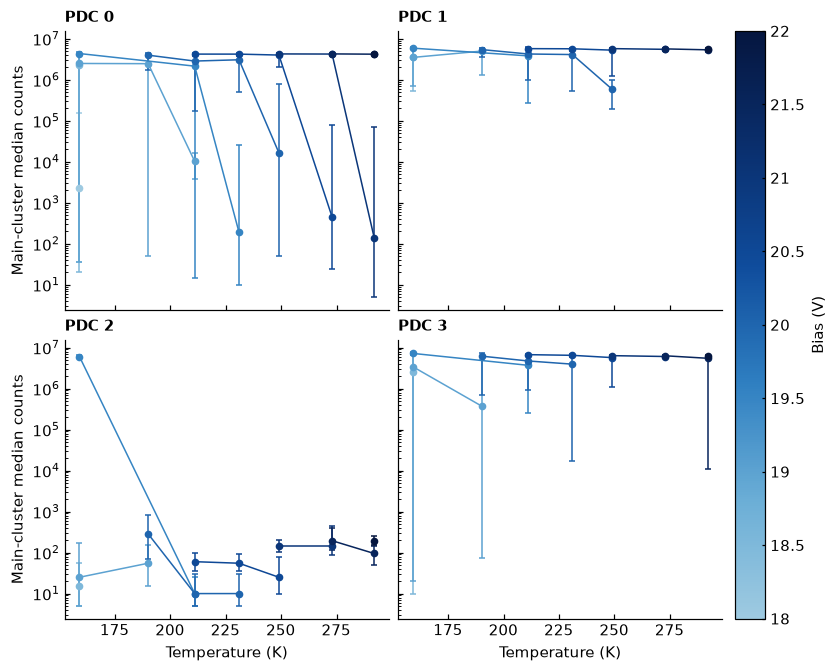

Saved tcr_cluster_vs_bias to C:\Users\p6k\Desktop\UCSDPDCv2\data\TCR_Temp_Bias


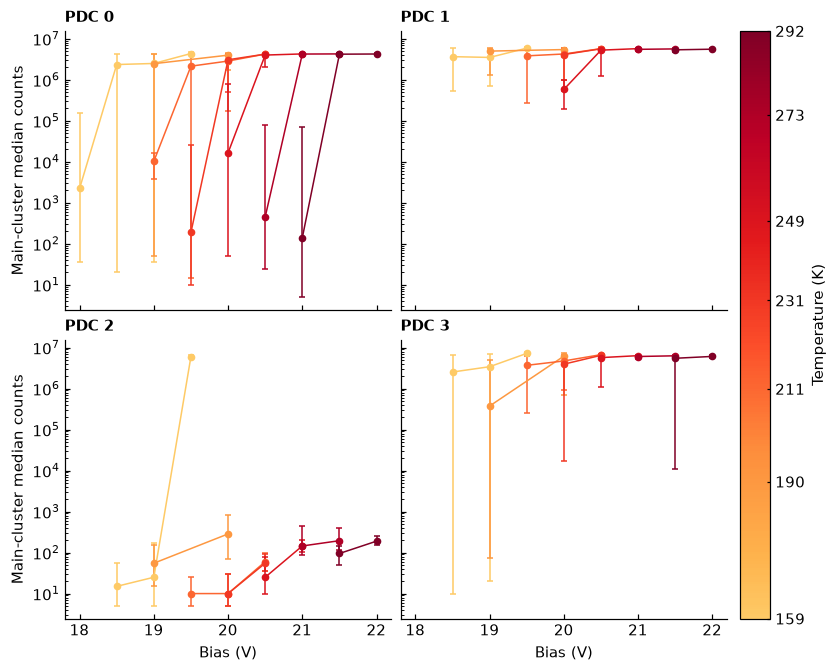

In [92]:
LABELS = {"temp": ("Temperature (K)", "K"), "bias": ("Bias (V)", "V")}
YLABELS = {"cluster": "Main-cluster median counts", "mode": "Mode counts", "median": "Median counts"}


def active_pdcs(results, col, what):
    """PDCs with at least one non-zero, non-NaN value in col; others are skipped."""
    keep = [p for p, g in results.groupby("pdc") if (g[col].fillna(0) != 0).any()]
    skipped = sorted(set(results["pdc"]) - set(keep))
    if skipped:
        print(f"{what}: skipping PDC {skipped} (all values are zero)")
    return keep


def save_fig(fig, name):
    if not SAVE_PLOTS:
        return
    folder = Path(SAVE_DIR).expanduser() if SAVE_DIR else parent
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / f"{name}.png")
    print(f"Saved {name} to {folder}")


def plot_tcr(results, x):
    """One panel per PDC; x is 'temp' or 'bias'; the other quantity (if enabled) is the colour."""
    by = next((a for a in axes_present if a != x), None)
    pdcs = active_pdcs(results, "value", "TCR plot")
    if not pdcs:
        return
    fig, axs = pdc_grid(len(pdcs), FIG_SCALE)
    groups = [(None, results)] if by is None else list(results.groupby(by))
    levels = [key for key, _ in groups]

    for ax, pdc in zip(axs, pdcs):
        for key, g in groups:
            color = "k" if by is None else hue_color(by, key, levels)
            g = g[g["pdc"] == pdc].sort_values(x)
            err = np.clip([g["value"] - g["p16"], g["p84"] - g["value"]], 0, None) if SHOW_SPREAD else None
            ax.errorbar(g[x], g["value"], yerr=err, color=color, marker="o", ms=4, lw=1, capsize=2)
            if SHOW_MINORITY:
                ax.scatter(g[x], g["minor"], s=25, facecolors="none", edgecolors=color)
        if LOG_Y:
            ax.set_yscale("log")
    label_grid(axs, pdcs, LABELS[x][0], YLABELS[ESTIMATOR])
    if by is not None:
        add_hue_colorbar(fig, axs, by, levels)
    save_fig(fig, f"tcr_{ESTIMATOR}_vs_{x}")
    plt.show()


for x in axes_present:
    plot_tcr(results, x)

### Off pixels and bimodal tests

Saved off_pixels_vs_temp to C:\Users\p6k\Desktop\UCSDPDCv2\data\TCR_Temp_Bias


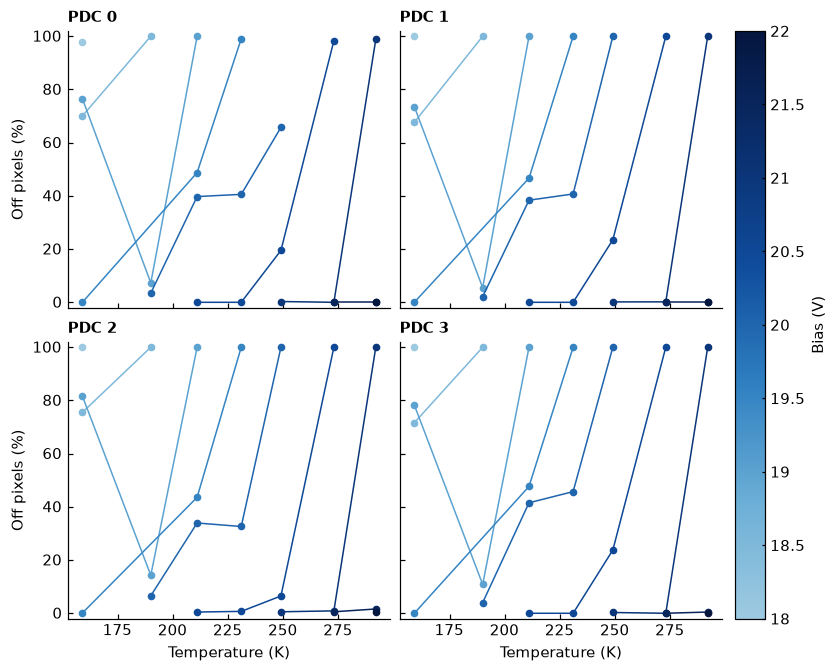

Saved off_pixels_vs_bias to C:\Users\p6k\Desktop\UCSDPDCv2\data\TCR_Temp_Bias


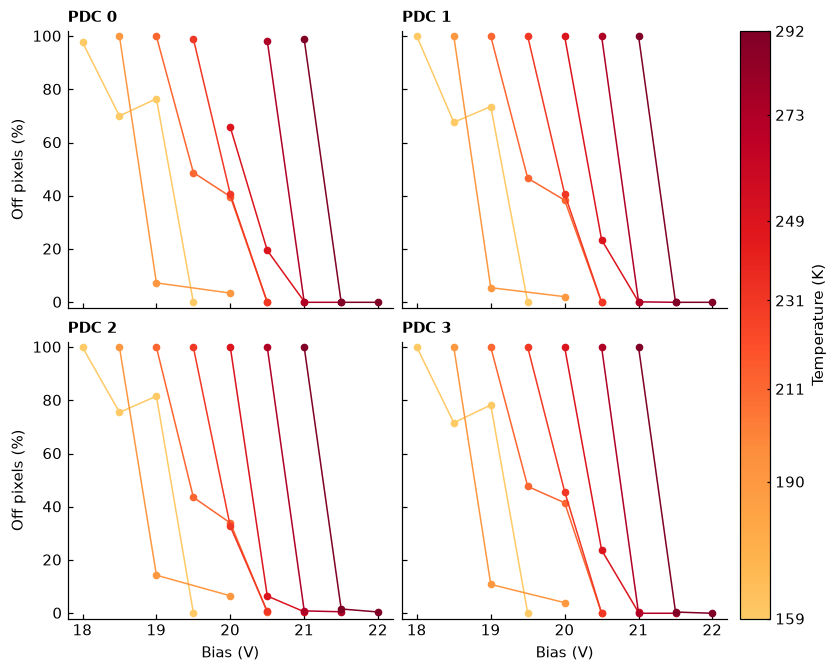

In [93]:
def plot_off(results, x):
    """Off-pixel count (TCR = 0) per PDC; same layout as plot_tcr."""
    by = next((a for a in axes_present if a != x), None)
    pdcs = active_pdcs(results, "n_off", "off-pixel plot")
    if not pdcs:
        return
    fig, axs = pdc_grid(len(pdcs), FIG_SCALE)
    groups = [(None, results)] if by is None else list(results.groupby(by))
    levels = [key for key, _ in groups]

    for ax, pdc in zip(axs, pdcs):
        for key, g in groups:
            color = "k" if by is None else hue_color(by, key, levels)
            g = g[g["pdc"] == pdc].sort_values(x)
            ax.plot(g[x], 100*g["n_off"]/g["n"], color=color, marker="o", ms=4, lw=1)
    label_grid(axs, pdcs, LABELS[x][0], "Off pixels (%)")
    axs[0].set_ylim(-2, 102)
    if by is not None:
        add_hue_colorbar(fig, axs, by, levels)
    save_fig(fig, f"off_pixels_vs_{x}")
    plt.show()


for x in axes_present:
    plot_off(results, x)

cols = [*axes_present, "pdc", "value", "minor", "minor_frac", "n_off", "n"]
#results.loc[results["bimodal"] | (results["n_off"] > 0), cols].round(3)

PDC 0, 249 K: off pixels never fall through 80% in the scanned range; skipped
pdc         0       1       2       3
temp                                 
292.0  21.095  21.100  21.102  21.100
273.0  20.593  20.600  20.601  20.600
249.0     NaN  20.130  20.107  20.131
231.0  19.663  19.669  19.648  19.684
211.0  19.195  19.187  19.177  19.191
190.0  18.608  18.606  18.617  18.612
159.0  18.320  18.309  18.408  18.352
     k_mV_per_K  k_err      V0  V0_err     r2  n_temps
pdc                                                   
0        21.683  1.301  21.032   0.106  0.986        6
1        21.887  1.143  21.052   0.088  0.987        7
2        21.306  1.388  21.023   0.107  0.979        7
3        21.636  1.229  21.046   0.095  0.984        7
Saved vbd_vs_temp to C:\Users\p6k\Desktop\UCSDPDCv2\data\TCR_Temp_Bias


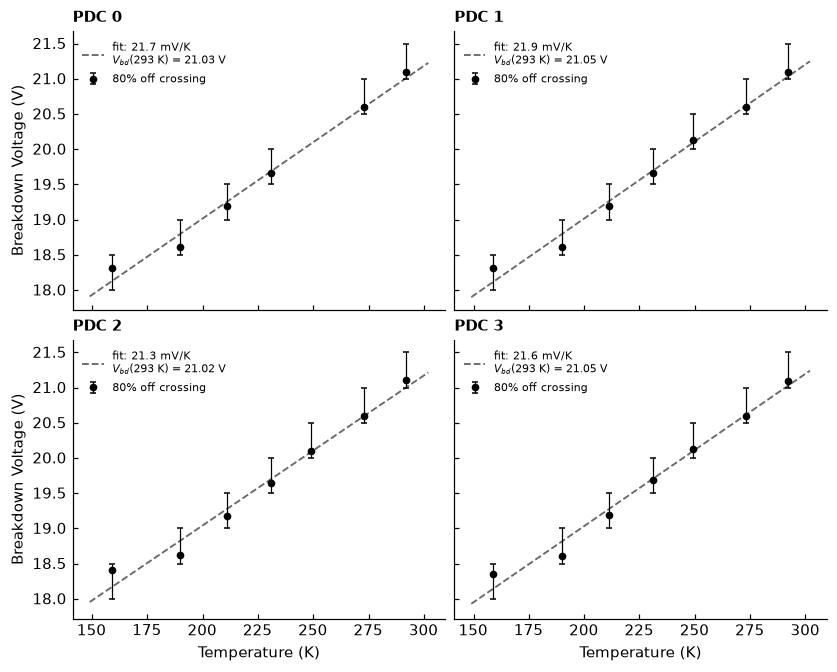

In [94]:
VBD_LEVEL = 80.0                     # "breakdown" = this % of pixels off


def breakdown_voltages(results, level=VBD_LEVEL):
    """Per (pdc, temp): bias where the off-pixel fraction first falls through `level` %,
    by linear interpolation between the two bracketing bias points."""
    rows = []
    for (pdc, temp), g in results.groupby(["pdc", "temp"]):
        g = g.sort_values("bias")
        b = g["bias"].to_numpy(float)
        off = 100 * g["n_off"].to_numpy(float) / g["n"].to_numpy(float)
        hit = np.where((off[:-1] > level) & (off[1:] <= level))[0]
        if hit.size == 0:
            print(f"PDC {pdc}, {temp:g} K: off pixels never fall through {level:g}% in the scanned range; skipped")
            continue
        i = hit[0]
        v = b[i] + (b[i + 1] - b[i]) * (off[i] - level) / (off[i] - off[i + 1])
        rows.append(dict(pdc=pdc, temp=temp, vbd=v, v_lo=b[i], v_hi=b[i + 1]))
    return pd.DataFrame(rows)


def fit_vbd(vbd, t0=293.0):
    """Linear fit V_bd = V0 + k (T - t0) per PDC."""
    rows = []
    for pdc, g in vbd.groupby("pdc"):
        if len(g) < 2:
            continue
        T, V = g["temp"].to_numpy(float) - t0, g["vbd"].to_numpy(float)
        if len(g) > 2:
            (k, c), cov = np.polyfit(T, V, 1, cov=True)
            ek, ec = np.sqrt(np.diag(cov))
        else:
            (k, c), (ek, ec) = np.polyfit(T, V, 1), (np.nan, np.nan)
        r2 = 1 - np.sum((V - (k * T + c)) ** 2) / np.sum((V - V.mean()) ** 2)
        rows.append(dict(pdc=pdc, k_mV_per_K=1e3 * k, k_err=1e3 * ek, V0=c, V0_err=ec, r2=r2, n_temps=len(g)))
    return pd.DataFrame(rows).set_index("pdc")


def plot_vbd(vbd, fits, t0=293.0):
    pdcs = list(fits.index)
    fig, axs = pdc_grid(len(pdcs), FIG_SCALE)
    Tfit = np.linspace(vbd["temp"].min() - 10, vbd["temp"].max() + 10, 50)
    for a, pdc in zip(axs, pdcs):
        g = vbd[vbd["pdc"] == pdc].sort_values("temp")
        f = fits.loc[pdc]
        yerr = [g["vbd"] - g["v_lo"], g["v_hi"] - g["vbd"]]          # bracketing bias step
        a.errorbar(g["temp"], g["vbd"], yerr=yerr, fmt="o", color="k", ms=4, lw=0.8, capsize=2, zorder=3,
                   label=f"{VBD_LEVEL:g}% off crossing")
        a.plot(Tfit, f["V0"] + 1e-3 * f["k_mV_per_K"] * (Tfit - t0), color="0.4", ls="--", lw=1.2,
               label=f"fit: {f['k_mV_per_K']:.1f} mV/K\n$V_{{bd}}$({t0:g} K) = {f['V0']:.2f} V")
        a.legend(fontsize=7, loc="upper left", frameon=False)
    label_grid(axs, pdcs, "Temperature (K)", "Breakdown Voltage (V)")
    save_fig(fig, "vbd_vs_temp")
    plt.show()


if not (USE_TEMP and USE_BIAS):
    raise ValueError("Breakdown vs temperature needs both USE_TEMP and USE_BIAS")

vbd = breakdown_voltages(results)
print(vbd.pivot(index="temp", columns="pdc", values="vbd").sort_index(ascending=False).round(3))
vbd_fits = fit_vbd(vbd)
print(vbd_fits.round(3))
plot_vbd(vbd, vbd_fits)

### Inspect one distribution

Shows the pixel TCR histogram (log10) with the plain median (dotted) next to the estimator value (solid) and the minority cluster (dashed).

In [95]:
def inspect(results, pdc=None, temp=None, bias=None, bins=40):
    pdc = results["pdc"].min() if pdc is None else pdc
    sel = results["pdc"] == pdc
    for name, val in (("temp", temp), ("bias", bias)):
        if name in results and val is not None:
            sel &= np.isclose(results[name], val)
    if not sel.any():
        raise ValueError(f"No result for pdc={pdc}, temp={temp}, bias={bias}")
    row = results[sel].iloc[0]
    tcr = pd.read_csv(row["file"], delimiter=DELIMITER)[f"SPAD_TCR{pdc}"].to_numpy(float)
    live = tcr[tcr > 0]

    fig, ax = plt.subplots(figsize=(FIG_SCALE * 2, FIG_SCALE))
    ax.hist(np.log10(live), bins=bins, color="0.7", edgecolor="k", lw=0.5)
    ax.axvline(np.log10(max(row["median"], 1e-9)), color="k", ls=":", label=f"median = {row['median']:.3g}")
    ax.axvline(np.log10(row["value"]), color="k", ls="-", label=f"{ESTIMATOR} = {row['value']:.3g}")
    if row["bimodal"]:
        ax.axvline(np.log10(row["minor"]), color="k", ls="--", label=f"minority = {row['minor']:.3g} ({row['minor_frac']:.0%})")
    ax.set_xlabel("log10(TCR counts)")
    ax.set_ylabel("Pixels")
    ax.set_title(f"PDC {pdc}  " + "  ".join(f"{k}={row[k]:g}" for k in axes_present) + f"  ({row['n_off']} off)")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


inspect(results, bias=25)

ValueError: No result for pdc=0, temp=None, bias=25